In [ ]:
import pandas as pd
import glob
import os

# Define the list of CSV files to merge
files_to_merge = [
    '/content/drive/MyDrive/ML college project folder/YouTube_Live_1.csv',
    '/content/drive/MyDrive/ML college project folder/YouTube_Live_2.csv',
    '/content/drive/MyDrive/ML college project folder/YouTube_Live_3.csv',
    '/content/drive/MyDrive/ML college project folder/YouTube_Live_4.csv',
    '/content/drive/MyDrive/ML college project folder/YouTube_Live_5.csv',
]

# Filter to include only files that exist
existing_files = [f for f in files_to_merge if os.path.exists(f)]

if existing_files:
    print(f"Merging these files: {existing_files}")
    dfs = []
    for f in existing_files:
        # Try multiple common encodings to prevent UnicodeDecodeError
        try:
            df = pd.read_csv(f, encoding='utf-8')
        except UnicodeDecodeError:
            try:
                df = pd.read_csv(f, encoding='utf-8-sig')
            except UnicodeDecodeError:
                df = pd.read_csv(f, encoding='cp1252') # common Windows encoding
        dfs.append(df)

    merged_df = pd.concat(dfs, ignore_index=True)

    # Save the merged DataFrame using utf-8 encoding
    merged_filename = 'youtube_live_merged.csv'
    merged_df.to_csv(merged_filename, index=False, encoding='utf-8')
    print(f"Successfully merged files into '{merged_filename}'!")
    display(merged_df.head())
else:
    print("Error: No matching 'youtube live' CSV files found. Please check your Drive paths.")

Merging these files: ['/content/drive/MyDrive/ML college project folder/YouTube_Live_1.csv', '/content/drive/MyDrive/ML college project folder/YouTube_Live_2.csv', '/content/drive/MyDrive/ML college project folder/YouTube_Live_3.csv', '/content/drive/MyDrive/ML college project folder/YouTube_Live_4.csv', '/content/drive/MyDrive/ML college project folder/YouTube_Live_5.csv']
Successfully merged files into 'youtube_live_merged.csv'!


,No.,Time,Source,Destination,Protocol,Length,Info
0,87,2022-05-30 08:25:18.220269,10.215.173.1,142.251.72.7,GQUIC,1278,"Client Hello, PKN: 1, CID: 4472406183105229454"
1,88,2022-05-30 08:25:18.222899,10.215.173.1,142.251.72.7,GQUIC,936,"Payload (Encrypted), PKN: 2, CID: 447240618310..."
2,89,2022-05-30 08:25:18.222949,10.215.173.1,142.251.72.7,GQUIC,817,"Payload (Encrypted), PKN: 3, CID: 447240618310..."
3,90,2022-05-30 08:25:18.222975,10.215.173.1,142.251.72.7,GQUIC,931,"Payload (Encrypted), PKN: 4, CID: 447240618310..."
4,91,2022-05-30 08:25:18.222994,10.215.173.1,142.251.72.7,GQUIC,931,"Payload (Encrypted), PKN: 5, CID: 447240618310..."


In [ ]:
from google.colab import files
import os

merged_filename = 'youtube_live_merged.csv'

if os.path.exists(merged_filename):
    print(f"Triggering download for {merged_filename}...")
    files.download(merged_filename)
else:
    print(f"Error: '{merged_filename}' does not exist. Please make sure the merge cell ran successfully first.")

Triggering download for youtube_live_merged.csv...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Step 1: Inspect the Dataset
We will check the overall shape, columns, data types, and identify missing values.

In [ ]:
import pandas as pd

# Load the merged CSV file back into memory
try:
    df_merged = pd.read_csv('youtube_live_merged.csv')
    print("Dataset loaded successfully!")

    # Calculating dataset shape
    print("Dataset shape:")
    print(df_merged.shape)

except FileNotFoundError:
    print("Error: 'youtube_live_merged.csv' not found. Please upload or recreate the file first.")


Dataset loaded successfully!
Dataset shape:
(6263188, 7)


In [ ]:
#column names
print("\nColumn names:")
print(df_merged.columns)



Column names:
Index(['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info'], dtype='object')


In [ ]:
#data types:
print("\nData types:")
print(df_merged.dtypes)



Data types:
No.             int64
Time           object
Source         object
Destination    object
Protocol       object
Length          int64
Info           object
dtype: object


In [ ]:
print("\nBasic information:")
df_merged.info()



Basic information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6263188 entries, 0 to 6263187
Data columns (total 7 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   No.          int64 
 1   Time         object
 2   Source       object
 3   Destination  object
 4   Protocol     object
 5   Length       int64 
 6   Info         object
dtypes: int64(2), object(5)
memory usage: 334.5+ MB


In [ ]:
print("\nStatistical information:")
display(df_merged.describe(include='all'))


Statistical information:


,No.,Time,Source,Destination,Protocol,Length,Info
count,6.263188e+06,6263188,6263188,6263188,6263188,6.263188e+06,6262725
unique,NaN,6263188,112,113,14,NaN,97467
top,NaN,2022-05-30 08:25:18.220269,211.114.67.81,10.215.173.1,GQUIC,NaN,Protected Payload (KP0)
freq,NaN,1,2819502,5712397,4395234,NaN,222026
mean,9.860639e+05,NaN,NaN,NaN,NaN,1.080478e+03,NaN
std,8.640162e+05,NaN,NaN,NaN,NaN,4.140609e+02,NaN
min,1.000000e+00,NaN,NaN,NaN,NaN,4.000000e+01,NaN
25%,3.231088e+05,NaN,NaN,NaN,NaN,1.278000e+03,NaN
50%,6.695700e+05,NaN,NaN,NaN,NaN,1.278000e+03,NaN
75%,1.482513e+06,NaN,NaN,NaN,NaN,1.278000e+03,NaN


In [ ]:
print("Missing Values")
print(df_merged.isnull().sum())

Missing Values
No.              0
Time             0
Source           0
Destination      0
Protocol         0
Length           0
Info           463
dtype: int64


In [ ]:
# Check for duplicates
num_duplicates = df_merged.duplicated().sum()
print("Duplicates:")
if num_duplicates > 0:
    print(f"There are {num_duplicates} duplicate rows in the dataset.")
    print(f"Percentage of duplicate rows: {(num_duplicates / len(df_merged)) * 100:.2f}%")
else:
    print("There are no duplicate rows in the dataset.")

Duplicates:
There are no duplicate rows in the dataset.


### Step 2: Handle Missing Values
We will drop rows that have critical missing values or fill them appropriately.

In [ ]:
# Drop rows where essential columns like 'Source' or 'Destination' are missing
df_merged = df_merged.dropna(subset=['Source', 'Destination', 'Time'])

# Fill any missing values in 'Info' with a placeholder
if 'Info' in df_merged.columns:
    df_merged['Info'] = df_merged['Info'].fillna('Unknown')

print("Remaining missing values:")
print(df_merged.isnull().sum())

Remaining missing values:
No.            0
Time           0
Source         0
Destination    0
Protocol       0
Length         0
Info           0
dtype: int64


### Step 3: Understand the Target Variable
Our target variable is `Protocol`. Let's inspect the unique protocols present in our dataset and count their occurrences.

In [ ]:
# Check the unique protocol values
print("Unique protocols in the dataset:")
print(df_merged["Protocol"].unique())

print("\nProtocol counts:")
print(df_merged["Protocol"].value_counts())

Unique protocols in the dataset:
['GQUIC' 'TCP' 'DNS' 'QUIC' 'TLSv1.3' 'UDP' 'DCP-AF' 'DCP-PFT' 'R-GOOSE'
 'THRIFT' 'CLTP' 'MPEG TS' 'TLSv1' 'ar_drone']

Protocol counts:
Protocol
GQUIC       4395234
UDP         1552972
QUIC         309325
TCP            2499
TLSv1.3        1930
DNS             520
R-GOOSE         303
DCP-PFT         165
DCP-AF          163
THRIFT           38
TLSv1            22
MPEG TS           9
CLTP              7
ar_drone          1
Name: count, dtype: int64


/tmp/ipykernel_3412/3737047024.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


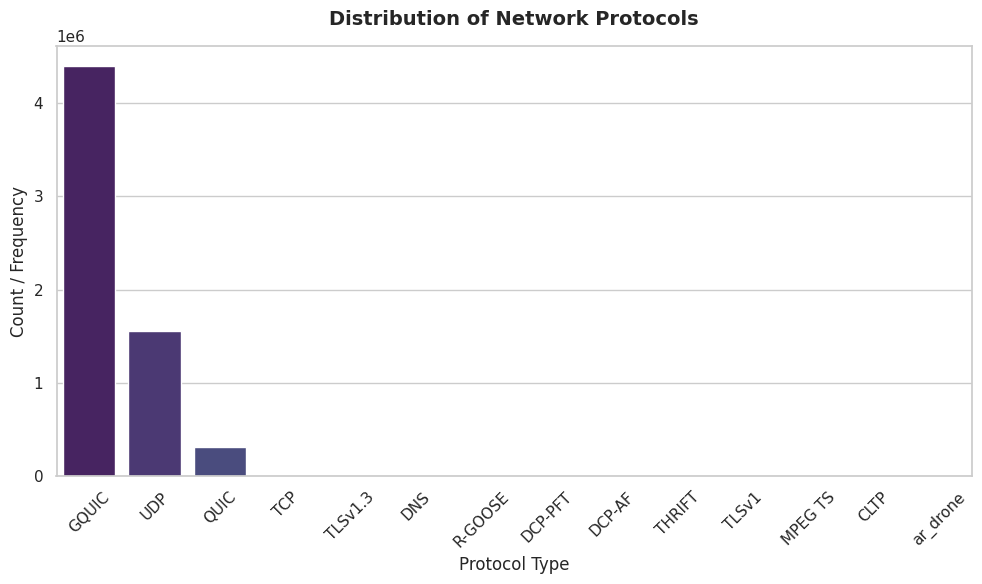

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style for cleaner visuals
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 1. Create a bar plot of protocol counts
# ordering by value counts makes the chart much easier to read
sns.countplot(
    data=df_merged,
    x="Protocol",
    order=df_merged["Protocol"].value_counts().index,
    palette="viridis"
)

# Add labels and styling
plt.title("Distribution of Network Protocols", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Protocol Type", fontsize=12)
plt.ylabel("Count / Frequency", fontsize=12)
plt.xticks(rotation=45) # Rotates labels so they don't overlap

# Clean up layout and display
plt.tight_layout()
plt.show()


### Step 5: Calculate Packet Length
In this step, we analyze the characteristics of packet sizes (length) using descriptive statistics to understand the transmission patterns across different protocols.

In [ ]:
# Display descriptive statistics for packet lengths
print("Packet Length Statistics:")
print(df_merged['Length'].describe())

# Calculate and print specific metrics
print(f"\nMinimum Packet Length: {df_merged['Length'].min()} bytes")
print(f"Maximum Packet Length: {df_merged['Length'].max()} bytes")
print(f"Average Packet Length: {df_merged['Length'].mean():.2f} bytes")

Packet Length Statistics:
count    6.263188e+06
mean     1.080478e+03
std      4.140609e+02
min      4.000000e+01
25%      1.278000e+03
50%      1.278000e+03
75%      1.278000e+03
max      1.000000e+04
Name: Length, dtype: float64

Minimum Packet Length: 40 bytes
Maximum Packet Length: 10000 bytes
Average Packet Length: 1080.48 bytes


### Step 6: Convert 'Time' Column to Datetime Format
We will parse the 'Time' column to actual datetime objects and sort the data chronologically.

In [ ]:
# Convert Time to datetime format
df_merged['Time'] = pd.to_datetime(df_merged['Time'], errors='coerce')

# Drop rows with invalid timestamps
df_merged = df_merged.dropna(subset=['Time'])

# Sort chronologically
df_merged = df_merged.sort_values(by='Time').reset_index(drop=True)

display(df_merged[['Time']].head())

,Time
0,2022-05-30 08:25:18.220269
1,2022-05-30 08:25:18.222899
2,2022-05-30 08:25:18.222949
3,2022-05-30 08:25:18.222975
4,2022-05-30 08:25:18.222994


### Step 7: Extract Time-based Features
We will extract temporal components like Hour, Minute, and Second to help ML models detect patterns over time.

In [ ]:
# Extract temporal features
df_merged['Hour'] = df_merged['Time'].dt.hour
df_merged['Minute'] = df_merged['Time'].dt.minute
df_merged['Second'] = df_merged['Time'].dt.second

display(df_merged[['Time', 'Hour', 'Minute', 'Second']].head())

,Time,Hour,Minute,Second
0,2022-05-30 08:25:18.220269,8,25,18
1,2022-05-30 08:25:18.222899,8,25,18
2,2022-05-30 08:25:18.222949,8,25,18
3,2022-05-30 08:25:18.222975,8,25,18
4,2022-05-30 08:25:18.222994,8,25,18


### Step 8: Numerical Feature Scaling
We will apply Min-Max scaling to the packet `Length` feature to map values between 0 and 1, making it optimized for machine learning training.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Scale the packet length
df_merged['Scaled_Length'] = scaler.fit_transform(df_merged[['Length']])

display(df_merged[['Length', 'Scaled_Length']].head())

,Length,Scaled_Length
0,1278,0.124297
1,936,0.089960
2,817,0.078012
3,931,0.089458
4,931,0.089458


### Step 9: Check X and y
In this step, we define our features ($X$) and target variable ($y$) from the preprocessed dataset, and inspect their shapes and contents to verify they are structured correctly for machine learning.

In [ ]:
# Define the target variable y and non-feature columns to drop from X
y_column = 'Protocol'
columns_to_drop_from_X = ['Source', 'Destination', 'Info', 'Protocol_Grouped', 'Protocol', 'Source_Group']

# Ensure we only select features that actually exist in df_merged
X_columns = [col for col in df_merged.columns if col not in columns_to_drop_from_X and col in df_merged.columns]

X = df_merged[X_columns]
y = df_merged[y_column]

# Display the shapes and preview X and y
print(f"Features (X) Shape: {X.shape}")
print(f"Target (y) Shape: {y.shape}")

print("\n--- First 5 rows of Features (X) ---")
display(X.head())

print("\n--- First 5 elements of Target (y) ---")
display(y.head())

Features (X) Shape: (6263188, 7)
Target (y) Shape: (6263188,)

--- First 5 rows of Features (X) ---


,No.,Time,Length,Hour,Minute,Second,Scaled_Length
0,87,2022-05-30 08:25:18.220269,1278,8,25,18,0.124297
1,88,2022-05-30 08:25:18.222899,936,8,25,18,0.089960
2,89,2022-05-30 08:25:18.222949,817,8,25,18,0.078012
3,90,2022-05-30 08:25:18.222975,931,8,25,18,0.089458
4,91,2022-05-30 08:25:18.222994,931,8,25,18,0.089458



--- First 5 elements of Target (y) ---


,Protocol
0,GQUIC
1,GQUIC
2,GQUIC
3,GQUIC
4,GQUIC


### Step 10: Handle Missing Feature Values
In this step, we verify if our selected features in $X$ contain any missing (`NaN` or null) values. Handling missing values in our features is critical because standard scikit-learn algorithms cannot handle raw `NaN` inputs. If any missing values are detected, we will fill them using column-wise median values to maintain numerical robustness.

In [ ]:
# Check for missing values in X
missing_counts = X.isnull().sum()
print("Missing values per feature in X:")
print(missing_counts)

# Handle missing values if any exist
if missing_counts.sum() > 0:
    print("\nFound missing values! Imputing missing values with column medians...")
    # Impute missing values with column median values
    X = X.fillna(X.median())
    print("Missing values after imputation:")
    print(X.isnull().sum())
else:
    print("\nNo missing values found in features! $X$ is clean and ready.")

Missing values per feature in X:
No.              0
Time             0
Length           0
Hour             0
Minute           0
Second           0
Scaled_Length    0
dtype: int64

No missing values found in features! $X$ is clean and ready.


### Step 11: Encode the Target Labels with LabelEncoder
To prepare the target variable `Protocol` for training machine learning algorithms, we convert the categorical text labels into distinct numerical values using scikit-learn's `LabelEncoder`.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Initialize the LabelEncoder
le = LabelEncoder()

# Encode target labels
y_encoded = le.fit_transform(y)

# Display target mapping
for class_index, class_label in enumerate(le.classes_):
    print(f"{class_index}: {class_label}")

print(f"\nEncoded target shape: {y_encoded.shape}")

0: CLTP
1: DCP-AF
2: DCP-PFT
3: DNS
4: GQUIC
5: MPEG TS
6: QUIC
7: R-GOOSE
8: TCP
9: THRIFT
10: TLSv1
11: TLSv1.3
12: UDP
13: ar_drone

Encoded target shape: (6263188,)


### Step 12: Save the Fully Preprocessed Dataset
We will now drop any unneeded raw string columns (keeping the numeric/encoded versions) and save the final clean dataset.

In [ ]:
# Drop raw or redundant columns to make the dataset lighter
columns_to_drop = ['No.', 'Time', 'Protocol_Grouped']
final_df = df_merged.drop(columns=[col for col in columns_to_drop if col in df_merged.columns])

# Save to a final preprocessed CSV file
final_filepath = 'youtube_live_preprocessed_final.csv'
final_df.to_csv(final_filepath, index=False)
print(f"Fully preprocessed dataset with shape {final_df.shape} saved successfully to '{final_filepath}'!")

Fully preprocessed dataset with shape (6263188, 9) saved successfully to 'youtube_live_preprocessed_final.csv'!


### Step 13: Split the Dataset
To train our model and evaluate its generalization ability fairly, we split the feature matrix ($X$) and encoded target vector (`y_encoded`) into training (80%) and testing (20%) datasets. We utilize a stratified split because the protocol targets are highly imbalanced, ensuring the label distributions remain consistent between subsets.

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

# We have an extremely rare target class 'ar_drone' with only 1 sample.
# Stratification requires at least 2 samples per class. We will filter out this single row if present.
valid_mask = (y != 'ar_drone')
X_filtered = X[valid_mask]
y_encoded_filtered = y_encoded[valid_mask]

# Perform Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered,
    y_encoded_filtered,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded_filtered
)

print("Dataset splitting completed successfully:")
print(f"Training set shape: {X_train.shape} (Labels: {y_train.shape[0]})")
print(f"Testing set shape: {X_test.shape} (Labels: {y_test.shape[0]})")

Dataset splitting completed successfully:
Training set shape: (5010549, 7) (Labels: 5010549)
Testing set shape: (1252638, 7) (Labels: 1252638)


### Step 14: Feature Scaling
We apply `StandardScaler` to normalize our features (`No.`, `Time`, and `Length`). This ensures that the features have a mean of 0 and a standard deviation of 1, which is critical for optimization-based models like Logistic Regression.

In [ ]:
from sklearn.preprocessing import StandardScaler

# We need numerical features only for scaling
# Convert Time to timestamp float to allow scaling
X_train_numeric = X_train.copy()
X_test_numeric = X_test.copy()

X_train_numeric['Time'] = pd.to_datetime(X_train_numeric['Time']).astype(np.int64) // 10**9
X_test_numeric['Time'] = pd.to_datetime(X_test_numeric['Time']).astype(np.int64) // 10**9

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_numeric)
X_test_scaled = scaler.transform(X_test_numeric)

print("Features scaled successfully!")

Features scaled successfully!


### Step 15: Model 1 - Logistic Regression


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Initialize the model
logistic_model = LogisticRegression(max_iter=1000, random_state=42)

# Fit the model on the scaled training data
print("Training Logistic Regression...")
logistic_model.fit(X_train_scaled, y_train)

# Predict on the scaled testing data
y_pred_lr = logistic_model.predict(X_test_scaled)

# Evaluate global accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print("Logistic Regression Accuracy:", accuracy_lr)
print(f"Accuracy in Percentage: {accuracy_lr * 100:.2f}%")

Training Logistic Regression...
Logistic Regression Accuracy: 0.9497125266836868
Accuracy in Percentage: 94.97%


### Step 16: Classification Report
To get a deeper understanding of our classifier's performance across different classes, we inspect precision, recall, and f1-score values.

In [ ]:
from sklearn.metrics import classification_report

# Generate classification report
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=[c for c in le.classes_ if c != 'ar_drone'],
    zero_division=0
))

              precision    recall  f1-score   support

        CLTP       0.00      0.00      0.00         1
      DCP-AF       0.00      0.00      0.00        33
     DCP-PFT       0.00      0.00      0.00        33
         DNS       0.00      0.00      0.00       104
       GQUIC       1.00      1.00      1.00    879047
     MPEG TS       0.00      0.00      0.00         2
        QUIC       0.00      0.00      0.00     61865
     R-GOOSE       0.00      0.00      0.00        61
         TCP       0.00      0.00      0.00       500
      THRIFT       0.00      0.00      0.00         8
       TLSv1       0.00      0.00      0.00         4
     TLSv1.3       0.83      0.01      0.03       386
         UDP       0.83      1.00      0.91    310594

    accuracy                           0.95   1252638
   macro avg       0.20      0.15      0.15   1252638
weighted avg       0.91      0.95      0.93   1252638



### Step 17: Confusion Matrix
We plot a heatmap representation of the confusion matrix to locate exactly where the predictions are aligned relative to true labels.

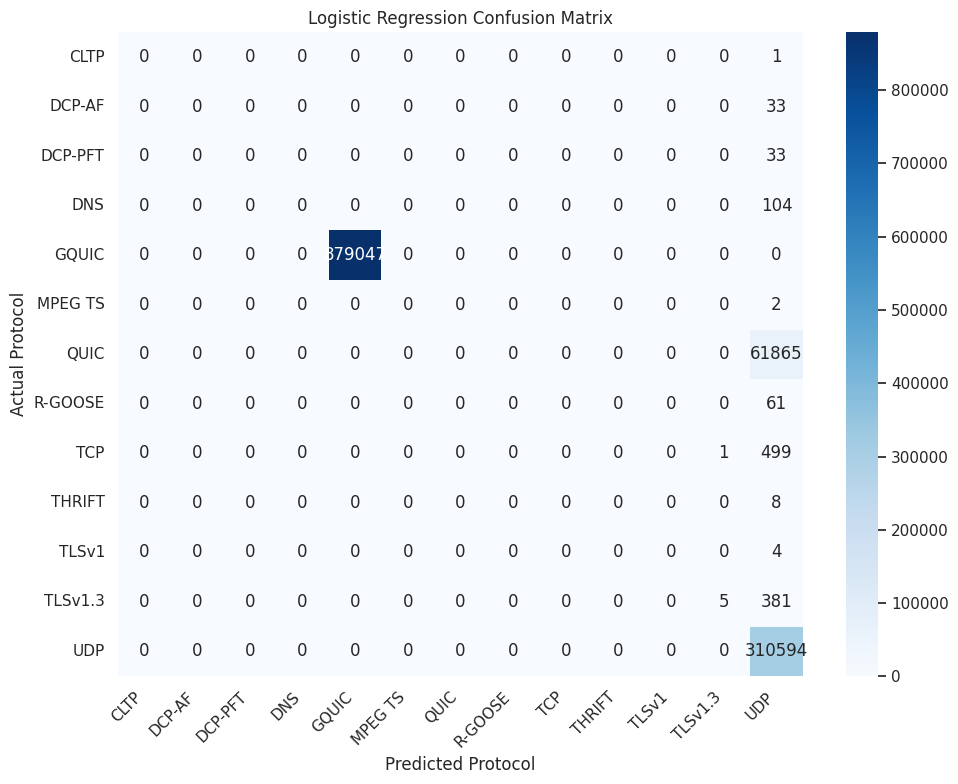

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)
classes = [c for c in le.classes_ if c != 'ar_drone']

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Logistic Regression Confusion Matrix")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Step 18: Model 2 - KNN


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Initialize the model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Fit the model on scaled training data (using a subset if memory constraint is an issue, but matching the user's snippet structure)
print("Training KNN...")
knn_model.fit(X_train_scaled[:50000], y_train[:50000])

# Predict on the scaled testing data
y_pred_knn = knn_model.predict(X_test_scaled[:50000])

# Evaluate global accuracy
accuracy_knn = accuracy_score(y_test[:50000], y_pred_knn)
print("KNN Accuracy:", accuracy_knn * 100, "%")

Training KNN...
KNN Accuracy: 98.428 %


### Step 19: Model 3 - Decision Tree


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Initialize the model
dt_model = DecisionTreeClassifier(random_state=42, max_depth=10)

# Fit the model on the numeric training data (not raw datetimes)
print("Training Decision Tree...")
dt_model.fit(X_train_numeric, y_train)

# Predict
y_pred_dt = dt_model.predict(X_test_numeric)

# Evaluate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", accuracy_dt * 100, "%")

Training Decision Tree...
Decision Tree Accuracy: 99.25804582010126 %


### Step 20: Visualize the Decision Tree


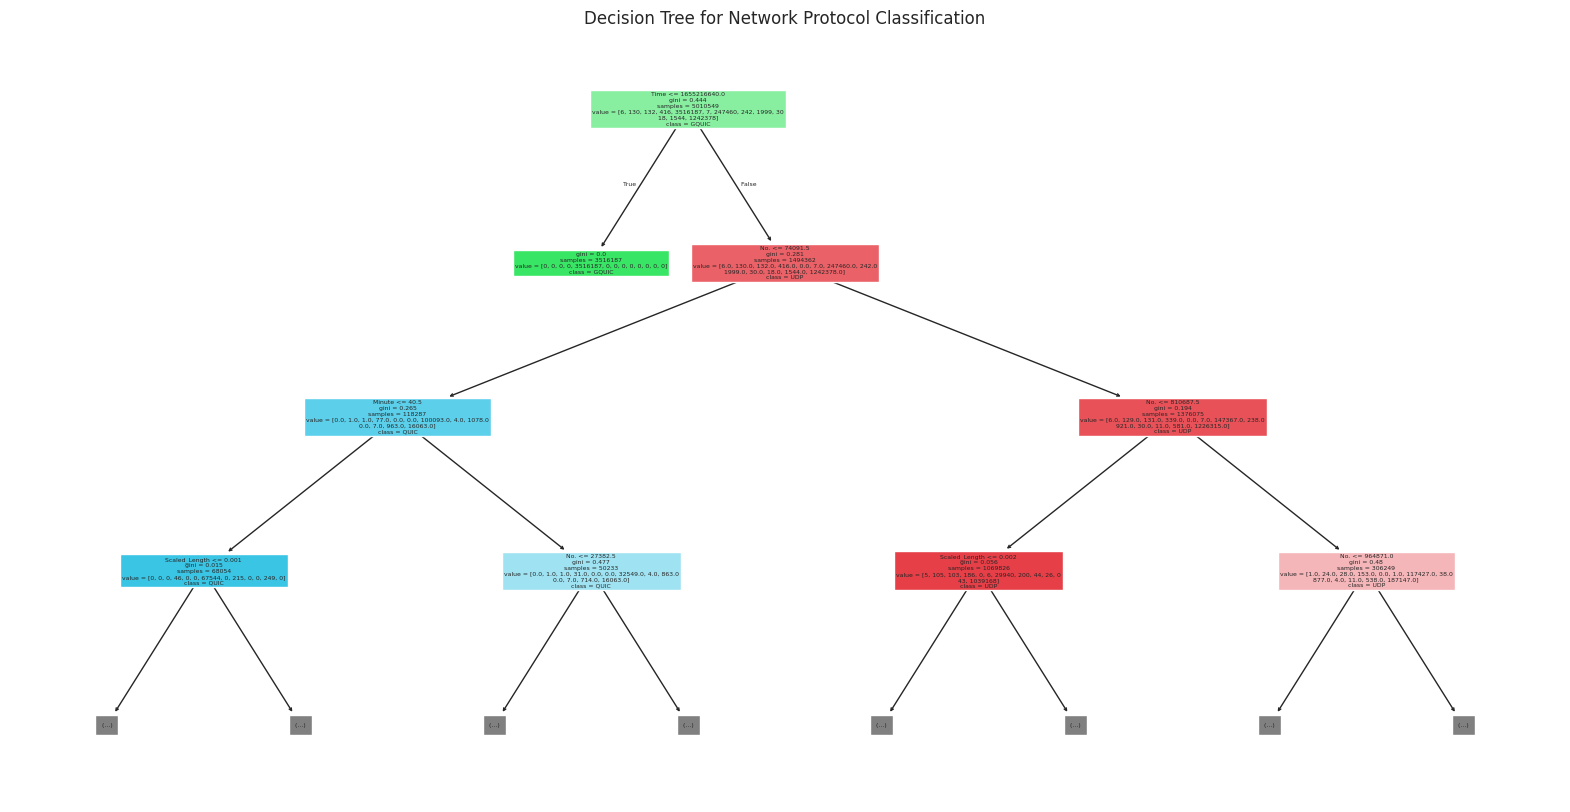

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[c for c in le.classes_ if c != 'ar_drone'],
    filled=True,
    max_depth=3
)

plt.title("Decision Tree for Network Protocol Classification")
plt.show()

### Step 21: Model 4 - Random Forest
Now introduce ensemble learning using Random Forest.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Initialize the model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# Fit the model on the numeric training data
print("Training Random Forest...")
rf_model.fit(X_train_numeric, y_train)

# Prediction
y_pred_rf = rf_model.predict(X_test_numeric)

# Accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", accuracy_rf * 100, "%")

Training Random Forest...
Random Forest Accuracy: 99.5868718656148 %


### Step 22: Compare All Models
We compile the accuracy scores achieved by all our trained classification algorithms and compare them in a summary table.

In [ ]:
import pandas as pd

# Construct comparison DataFrame
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_knn,
        accuracy_dt,
        accuracy_rf
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100
display(results)

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.949713,94.971253
1,KNN,0.984280,98.428000
2,Decision Tree,0.992580,99.258046
3,Random Forest,0.995869,99.586872


### Step 23: Plot Model Comparison
We plot a bar chart comparing the accuracy percentages of each machine learning model to visually identify the best performer.

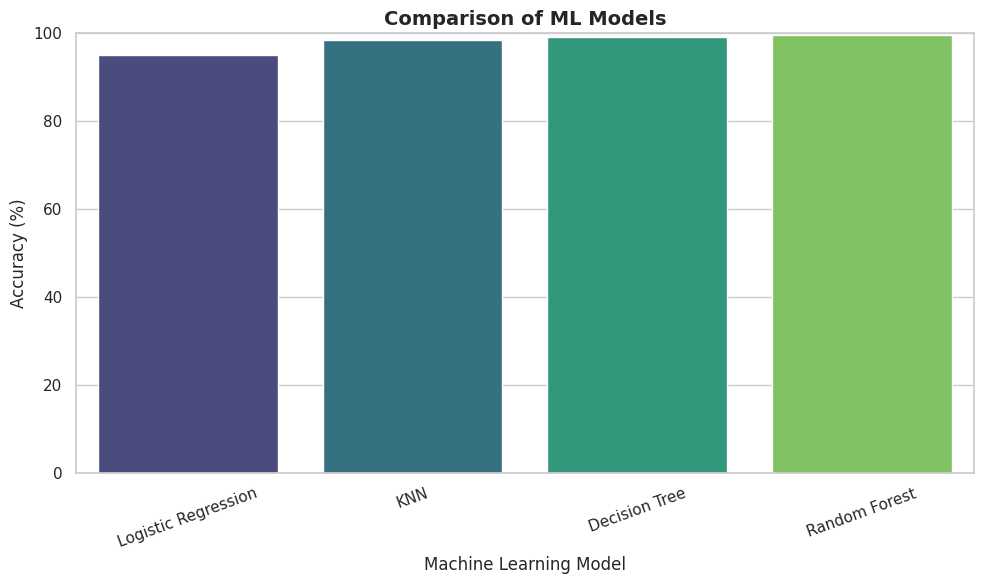

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)",
    palette="viridis",
    hue="Model",
    legend=False
)

plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.title("Comparison of ML Models", fontsize=14, fontweight='bold')
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Model")
plt.tight_layout()
plt.show()

### Step 24: Find the Best Model
We extract and display the model that obtained the highest accuracy score on the test subset.

In [ ]:
best_model = results.loc[results["Accuracy"].idxmax()]
print("Best Model:")
print(best_model)

Best Model:
Model           Random Forest
Accuracy             0.995869
Accuracy (%)        99.586872
Name: 3, dtype: object


### Step 25: Feature Importance
Let's analyze which numerical features contribute most heavily to the Random Forest model's decisions.

--- Feature Importance values ---
         Feature  Importance
1           Time    0.467142
3           Hour    0.307583
0            No.    0.131190
6  Scaled_Length    0.032924
2         Length    0.032389
4         Minute    0.021072
5         Second    0.007699


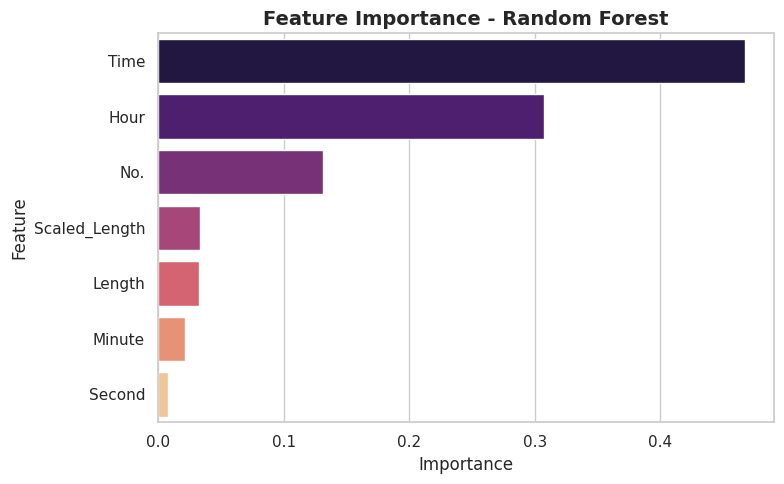

In [ ]:
# Random Forest feature importance
importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X_train_numeric.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("--- Feature Importance values ---")
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(8, 5))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    palette="magma",
    hue="Feature",
    legend=False
)
plt.title("Feature Importance - Random Forest", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Step 26: Detailed Evaluation of Random Forest
Now we generate a full classification report and a confusion matrix for our best overall performing model (Random Forest) to evaluate per-class precision and recall characteristics.

Classification Report for Random Forest:
              precision    recall  f1-score   support

        CLTP       0.00      0.00      0.00         1
      DCP-AF       0.00      0.00      0.00        33
     DCP-PFT       0.00      0.00      0.00        33
         DNS       0.51      0.25      0.34       104
       GQUIC       1.00      1.00      1.00    879047
     MPEG TS       0.00      0.00      0.00         2
        QUIC       0.97      0.96      0.96     61865
     R-GOOSE       0.00      0.00      0.00        61
         TCP       0.98      0.97      0.97       500
      THRIFT       0.00      0.00      0.00         8
       TLSv1       1.00      0.75      0.86         4
     TLSv1.3       0.85      0.80      0.82       386
         UDP       0.99      0.99      0.99    310594

    accuracy                           1.00   1252638
   macro avg       0.48      0.44      0.46   1252638
weighted avg       1.00      1.00      1.00   1252638



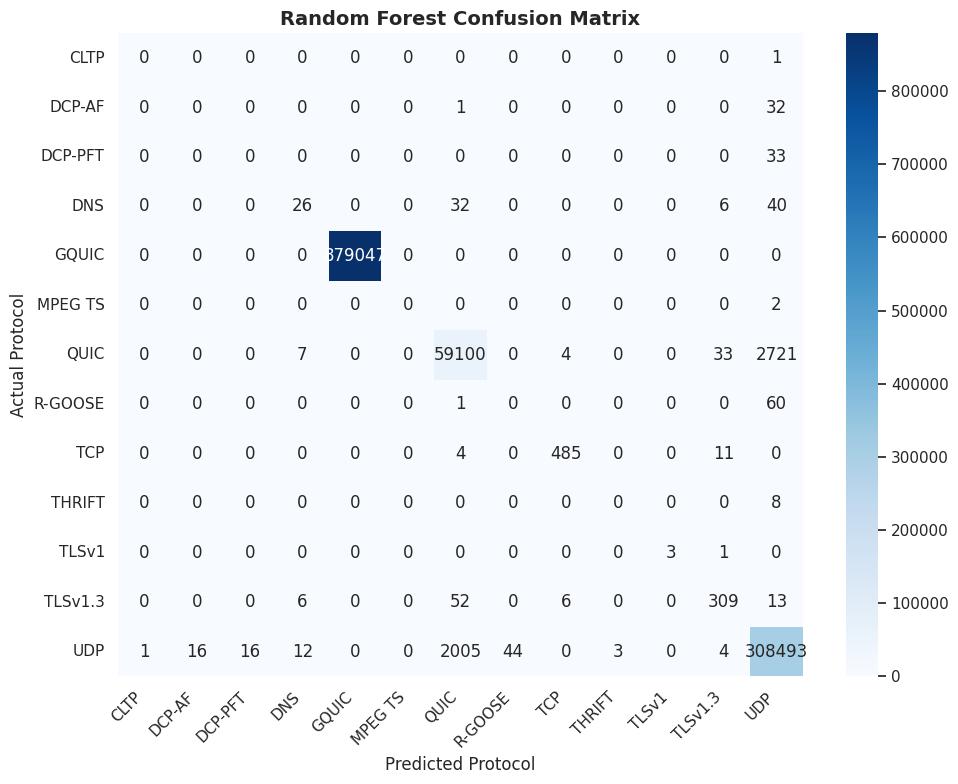

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Dynamic classes present excluding filtered elements
classes_present = [c for c in le.classes_ if c != 'ar_drone']

print("Classification Report for Random Forest:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=classes_present,
        zero_division=0
    )
)

# Construct and plot the confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes_present,
    yticklabels=classes_present
)
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Random Forest Confusion Matrix", fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Step 27: Predict a New Packet
Finally, we test our best model's predictive capabilities by feeding it custom features representing a simulated network packet and decoding the output class.

In [ ]:
import numpy as np
import pandas as pd

# 1. Define raw input values
no_val = 500000
time_val = 1653900000
length_val = 64

# 2. Build the initial DataFrame with all engineered time parts
new_packet = pd.DataFrame({
    "No.": [no_val],
    "Time": [time_val],
    "Length": [length_val]
})

# Extract time components
packet_time = pd.to_datetime(new_packet["Time"], unit='s')
new_packet["Hour"] = packet_time.dt.hour
new_packet["Minute"] = packet_time.dt.minute
new_packet["Second"] = packet_time.dt.second

# Create a temporary placeholder for Scaled_Length so the column exists
new_packet["Scaled_Length"] = new_packet["Length"]

# 3. Automatically arrange columns for the scaler
scaler_features = list(scaler.feature_names_in_)
new_packet_for_scaler = new_packet[scaler_features]

# 4. Transform using your scaler
new_packet_scaled_values = scaler.transform(new_packet_for_scaler)

# Create a clean DataFrame out of the scaled results
df_scaled = pd.DataFrame(new_packet_scaled_values, columns=scaler_features)

# --- THE FIX FOR THE MODEL ---
# 5. Automatically arrange columns in the exact order the rf_model wants
model_features = list(rf_model.feature_names_in_)
new_packet_processed = df_scaled[model_features]

# 6. Predict using the processed packet
prediction = rf_model.predict(new_packet_processed)

# 7. Convert prediction back to target string label
predicted_protocol = le.inverse_transform(prediction)

print("--- Custom Packet Prediction Demonstration ---")
print("Predicted Protocol:", predicted_protocol[0])


--- Custom Packet Prediction Demonstration ---
Predicted Protocol: GQUIC


### Step 28: Test the Prediction on Additional Simulated Packets
Let's perform additional test cases to verify the sensitivity of our trained Random Forest model to varying packet sizes and times.

In [ ]:
def predict_custom_packet(no_val, time_val, length_val):
    # 1. Build the raw input DataFrame
    packet = pd.DataFrame({
        "No.": [no_val],
        "Time": [time_val],
        "Length": [length_val]
    })

    # 2. Extract engineered features
    packet_time = pd.to_datetime(packet["Time"], unit='s')
    packet["Hour"] = packet_time.dt.hour
    packet["Minute"] = packet_time.dt.minute
    packet["Second"] = packet_time.dt.second
    packet["Scaled_Length"] = packet["Length"]

    # 3. Scale using the training pipeline order
    scaler_features = list(scaler.feature_names_in_)
    packet_for_scaler = packet[scaler_features]
    scaled_values = scaler.transform(packet_for_scaler)
    df_scaled = pd.DataFrame(scaled_values, columns=scaler_features)

    # 4. Align features for the Random Forest model
    model_features = list(rf_model.feature_names_in_)
    packet_processed = df_scaled[model_features]

    # 5. Predict and decode label
    pred_class = rf_model.predict(packet_processed)
    pred_protocol = le.inverse_transform(pred_class)[0]

    # Print clean results
    print("--- Custom Packet Prediction ---")
    print(f"Inputs -> No: {no_val} | Time: {time_val} | Length: {length_val} bytes")
    print(f"Predicted Protocol: {pred_protocol}\n")

    return pred_protocol


In [ ]:
# Test the 1278 bytes packet
predict_custom_packet(600000, 1654000000, 1278)


--- Custom Packet Prediction ---
Inputs -> No: 600000 | Time: 1654000000 | Length: 1278 bytes
Predicted Protocol: GQUIC



'GQUIC'